<a href="https://colab.research.google.com/github/mikahamelin-gif/IS-4487-final-project-nvidia/blob/main/IS_4487_Final_Project_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Read Me:
- Before working, click the arrow by "run all" and select "restart session and run all" to wipe the history and run all cells in order
- Commit changes to GitHub by saving after ***every time*** you edit it

# IS 4487 Final Project - NVIDIA

### Mikayla Hamelin, Beck Feely, Nathaniel Elbaum, Billy Ortiz


### Summary of business problem:

NVIDIA has to order chips from its manufacturing partners months before it sells them, while demand from AI data centers is growing fast and hard to predict. If it underestimates demand, it misses sales and customers turn to competitors. If it overestimates, it’s left with costly inventory it can’t sell. Our project forecasts how many AI chips NVIDIA should ship next quarter by proxy, by predicting estimated revenue for the next quarter, so it can plan production and capacity ahead of time.


## Business Problem & Context

### Description of the organization and the business challenge:

AI is the world's fastest growing market and technology, and this boom is supported largely by one company's technology: NVIDIA. NVIDIA designs graphics processing units (GPUs) and the software that runs them, and its chips have become the main hardware used to train and run AI models becuase of their ability to perform parallel processing, or runinng thousands of calculations at once. NVIDIA orders the chips they design from manufacturing partners months in advance. The challenge is predicting how many chips it will need when AI demand is growing quickly and changing from quarter to quarter.

### Why this problem matters (business impact)

Because of the nature of this industry, NVIDIA is in a precarious position. If NVIDIA orders too few chips, it misses sales and risks pushing its key buyers (cloud providers, AI companies, and other data center operators) toward competitors like AMD or toward building their own chips, as Google and Amazon already do. NVIDIA leads the AI chip market, so many other companies' operations and valuations depend on its supply, and some would argue the AI industry as a whole does too. If it orders too many, it ends up with expensive inventory that loses value as newer chips come out. Since production space has to be reserved well ahead of time, a better forecast helps NVIDIA plan capacity, manage costs, and keep its biggest customers and the broader AI industry supplied.

###Brief description of relevant industry or market factors
*  **Big tech spending**: Most demand comes from a few large companies like Microsoft,Google, Amazon and Meta, so changes in their data center budgets move NVIDIA’s sales.
*  **Supply limits**: Manufacturing capacity is limited and can’t be expanded quickly.
*   **Competition**: AMD, plus companies like Google and Amazon designing their own AI chips, could take share.
*   **Regulation and infrastructure**: U.S. export restrictions limit sales to some countries, and data centers need large amounts of power, which can slow how fast new ones get built.

## Data Sources & References

### Links to datasets used (original sources, not just download locations), & brief explanation of contents,

* https://epoch.ai/data-insights/hyperscaler-capex-trend -- aggregate data of capital expenditure since 2022 by the main players in the AI race. Epoch, in preparing the dataset, already accounted for the differences in how each company reports CAPEX spending and normalized it between the companies.

* https://www.sec.gov/edgar/browse/?CIK=0001045810 - SEC quarterly financial filings by NVIDIA as required because they're a public company. Data pulled in  bulk using a script.


* https://www.census.gov/construction/c30/historical_data.html -- historical and current data of public and private construction spend in various industries like office, commercial, etc. When datacenters are built, GPU orders aren't far behind.


### Citation of at least two credible references for the business context


*  NVIDIA Blog Announcing their partnership with TSMC in Arizona: https://blogs.nvidia.com/blog/nvidia-manufacture-american-made-ai-supercomputers-us/
*  NVIDIA SEC Report detailing their company, risks, and goals: https://www.sec.gov/Archives/edgar/data/1045810/000104581025000023/nvda-20250126.htm

## Data Acquisition & Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base = "https://raw.githubusercontent.com/mikahamelin-gif/IS-4487-final-project-nvidia/main/"

nvidia_url = base + "NVDA_Quarterly_Demand_Drivers.xlsx"
epoch_url = base + "epoch_hyperscaler_capex_2022_2025.csv"

census_url = "https://ourworldindata.org/grapher/monthly-spending-data-center-us.csv?v=1&csvType=full&useColumnShortNames=false"

In [ ]:
nvidia = pd.read_excel(
    nvidia_url,
    sheet_name="AI Chip Demand Drivers"
)

nvidia.columns = nvidia.columns.str.strip()

nvidia["quarter"] = (
    nvidia["Year"].astype(int).astype(str)
    + "Q"
    + nvidia["Quarter Number"].astype(int).astype(str)
)

nvidia = nvidia.sort_values("quarter")

print(nvidia[[
    "quarter",
    "NVDA Revenue ($mm)",
    "NVDA Data Center Revenue ($mm)"
]].head())

print("NVIDIA Shape:", nvidia.shape)

  quarter  NVDA Revenue ($mm)  NVDA Data Center Revenue ($mm)
0  2016Q1                1305                             143
1  2016Q2                1428                             151
2  2016Q3                2004                             240
3  2016Q4                2173                             296
4  2017Q1                1937                             409
NVIDIA Shape: (42, 44)


In [ ]:
epoch = pd.read_csv(epoch_url)

epoch.columns = epoch.columns.str.strip()

epoch["quarter"] = (
    epoch["Calendar Quarter"]
    .str.replace("CY", "", regex=False)
    .str.replace(" ", "", regex=False)
)

epoch = epoch.rename(columns={
    "MSFT Broad CapEx ($M)": "Microsoft_CapEx",
    "AMZN Broad CapEx ($M)": "Amazon_CapEx",
    "GOOG Broad CapEx ($M)": "Google_CapEx",
    "META Broad CapEx ($M)": "Meta_CapEx",
    "ORCL Broad CapEx ($M)": "Oracle_CapEx",
    "Total ($M)": "Total_Hyperscaler_CapEx"
})

capex_columns = [
    "Microsoft_CapEx",
    "Amazon_CapEx",
    "Google_CapEx",
    "Meta_CapEx",
    "Oracle_CapEx",
    "Total_Hyperscaler_CapEx"
]

for col in capex_columns:
    epoch[col] = pd.to_numeric(
        epoch[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

epoch = epoch.sort_values("quarter")

epoch["CapEx_YoY_Growth"] = (
    epoch["Total_Hyperscaler_CapEx"].pct_change(
        periods=4,
        fill_method=None
    ) * 100
)

epoch = epoch[
    ["quarter"] + capex_columns + ["CapEx_YoY_Growth"]
]

print(epoch.head())
print("Epoch Shape:", epoch.shape)

  quarter  Microsoft_CapEx  Amazon_CapEx  Google_CapEx  Meta_CapEx  \
0  2022Q1             6060         15117          9786        5556   
1  2022Q2             8011         15785          6828        7621   
2  2022Q3             6894         16509          7276        9375   
3  2022Q4             6872         16909          7595        9401   
4  2023Q1             7651         14215          6289        7062   

   Oracle_CapEx  Total_Hyperscaler_CapEx  CapEx_YoY_Growth  
0          1101                    37620               NaN  
1          1423                    39668               NaN  
2          1719                    41773               NaN  
3          2435                    43212               NaN  
4          2628                    37845          0.598086  
Epoch Shape: (16, 8)


In [ ]:

census_url = base + "privtime.xlsx"

census = pd.read_excel(
    census_url,
    sheet_name="Private NSA",
    header=3,
    usecols="A,J"
)

census.columns = ["Date", "Construction_Spending"]

census["Date"] = (
    census["Date"].astype(str)
    .str.extract(r"([A-Za-z]{3}-\d{2})")[0]
)

census["Date"] = pd.to_datetime(
    census["Date"],
    format="%b-%y",
    errors="coerce"
)

census["Construction_Spending"] = pd.to_numeric(
    census["Construction_Spending"],
    errors="coerce"
)

census = census.dropna(subset=["Date"])

census["quarter"] = (
    census["Date"].dt.to_period("Q").astype(str)
)

construction = census.groupby("quarter").agg(
    Construction_Spending=("Construction_Spending", "sum"),
    Months_Reported=("Construction_Spending", "count")
).reset_index()

construction.loc[
    construction["Months_Reported"] != 3,
    "Construction_Spending"
] = np.nan

print(construction.tail(10))
print("Construction Shape:", construction.shape)


    quarter  Construction_Spending  Months_Reported
125  2024Q2                 8106.0                3
126  2024Q3                 9645.0                3
127  2024Q4                10325.0                3
128  2025Q1                10930.0                3
129  2025Q2                12545.0                3
130  2025Q3                12875.0                3
131  2025Q4                13387.0                3
132  2026Q1                13724.0                3
133  2026Q2                17069.0                3
134  2026Q3                23414.0                3
Construction Shape: (135, 3)


In [ ]:

combined = pd.merge(
    nvidia,
    epoch,
    on="quarter",
    how="left"
)

combined = pd.merge(
    combined,
    construction,
    on="quarter",
    how="left"
)

combined = combined.sort_values("quarter").reset_index(drop=True)

print("Combined Dataset Shape:", combined.shape)

display(combined[[
    "quarter",
    "NVDA Revenue ($mm)",
    "NVDA Data Center Revenue ($mm)",
    "Total_Hyperscaler_CapEx",
    "Construction_Spending"
]].tail(15))


Combined Dataset Shape: (42, 53)


,quarter,NVDA Revenue ($mm),NVDA Data Center Revenue ($mm),Total_Hyperscaler_CapEx,Construction_Spending
27,2022Q4,6051,3600,43212.0,3349.0
28,2023Q1,7192,4300,37845.0,4078.0
29,2023Q2,13507,10300,36761.0,4647.0
30,2023Q3,18120,14500,40195.0,5377.0
31,2023Q4,22103,18400,46485.0,5893.0
32,2024Q1,26044,22600,49564.0,6721.0
33,2024Q2,30040,26300,60803.0,8106.0
34,2024Q3,35082,30800,66203.0,9645.0
35,2024Q4,39331,35600,83783.0,10325.0
36,2025Q1,44062,39100,82301.0,10930.0


In [ ]:
combined.to_csv("NVDA_Combined_Demand_Drivers.csv", index=False)

print("Combined dataset saved successfully!")
print("Rows:", len(combined))
print("Columns:", len(combined.columns))

Combined dataset saved successfully!
Rows: 42
Columns: 53


## Data Exploration (EDA)

In [ ]:
# initial inspection

display(combined.head())
display(combined.info())

,Quarter,Year,Quarter Number,Quarter End,SEC Fiscal Year,NVDA Revenue ($mm),NVDA Cost of Revenue ($mm),NVDA Gross Profit ($mm),NVDA R&D Expense ($mm),NVDA SG&A Expense ($mm),...,quarter,Microsoft_CapEx,Amazon_CapEx,Google_CapEx,Meta_CapEx,Oracle_CapEx,Total_Hyperscaler_CapEx,CapEx_YoY_Growth,Construction_Spending,Months_Reported
0,2016 Q1,2016,1,2016-05-01,2017,1305,554,751,346,159,...,2016Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,857.0,3
1,2016 Q2,2016,2,2016-07-31,2017,1428,602,826,350,157,...,2016Q2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1110.0,3
2,2016 Q3,2016,3,2016-10-30,2017,2004,821,1183,373,171,...,2016Q3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1137.0,3
3,2016 Q4,2016,4,2017-01-29,2017,2173,870,1303,394,176,...,2016Q4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1017.0,3
4,2017 Q1,2017,1,2017-04-30,2018,1937,787,1150,411,185,...,2017Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,941.0,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 53 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Quarter                                   42 non-null     object 
 1   Year                                      42 non-null     int64  
 2   Quarter Number                            42 non-null     int64  
 3   Quarter End                               42 non-null     object 
 4   SEC Fiscal Year                           42 non-null     int64  
 5   NVDA Revenue ($mm)                        42 non-null     int64  
 6   NVDA Cost of Revenue ($mm)                42 non-null     int64  
 7   NVDA Gross Profit ($mm)                   42 non-null     int64  
 8   NVDA R&D Expense ($mm)                    42 non-null     int64  
 9   NVDA SG&A Expense ($mm)                   42 non-null     int64  
 10  NVDA Operating Expenses ($mm)           

None

In [ ]:
## summary statistics
display(combined.describe(include="all"))

,Quarter,Year,Quarter Number,Quarter End,SEC Fiscal Year,NVDA Revenue ($mm),NVDA Cost of Revenue ($mm),NVDA Gross Profit ($mm),NVDA R&D Expense ($mm),NVDA SG&A Expense ($mm),...,quarter,Microsoft_CapEx,Amazon_CapEx,Google_CapEx,Meta_CapEx,Oracle_CapEx,Total_Hyperscaler_CapEx,CapEx_YoY_Growth,Construction_Spending,Months_Reported
count,42,42.000000,42.000000,42,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,...,42,16.000000,16.00000,16.000000,16.000000,16.000000,16.000000,12.000000,42.000000,42.0
unique,42,NaN,NaN,42,NaN,NaN,NaN,NaN,NaN,NaN,...,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2016 Q1,NaN,NaN,2016-05-01,NaN,NaN,NaN,NaN,NaN,NaN,...,2016Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,2020.761905,2.452381,NaN,2021.761905,16547.952381,4739.119048,11808.833333,1867.928571,559.261905,...,NaN,15701.562500,21017.12500,13102.312500,10688.125000,3999.875000,64509.000000,43.916907,4554.500000,3.0
std,NaN,3.074756,1.130560,NaN,3.074756,23367.481965,6007.915337,17475.319176,1714.408714,348.551152,...,NaN,8840.423692,8987.81317,6857.546157,5155.227817,3845.883113,32781.982411,35.392811,4330.756033,0.0
min,NaN,2016.000000,1.000000,NaN,2017.000000,1305.000000,554.000000,751.000000,346.000000,157.000000,...,NaN,6060.000000,11695.00000,6289.000000,5556.000000,1080.000000,36761.000000,-7.328325,857.000000,3.0
25%,NaN,2018.000000,1.250000,NaN,2019.000000,2936.750000,1079.500000,1829.750000,615.500000,259.500000,...,NaN,7921.000000,14925.00000,7515.250000,6932.250000,1611.250000,40063.250000,5.830235,1822.750000,3.0
50%,NaN,2021.000000,2.000000,NaN,2022.000000,5796.000000,2125.000000,3166.500000,1199.000000,541.500000,...,NaN,12997.000000,16709.00000,11515.500000,8605.500000,2369.000000,48024.500000,65.052699,2413.000000,3.0
75%,NaN,2023.000000,3.000000,NaN,2024.000000,21107.250000,5164.000000,15943.250000,2422.250000,706.250000,...,NaN,20549.250000,25874.50000,15371.750000,13921.500000,4443.000000,82671.500000,70.087087,5764.000000,3.0


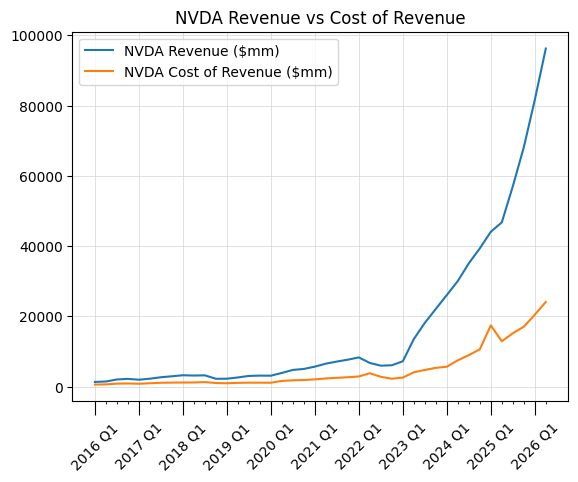

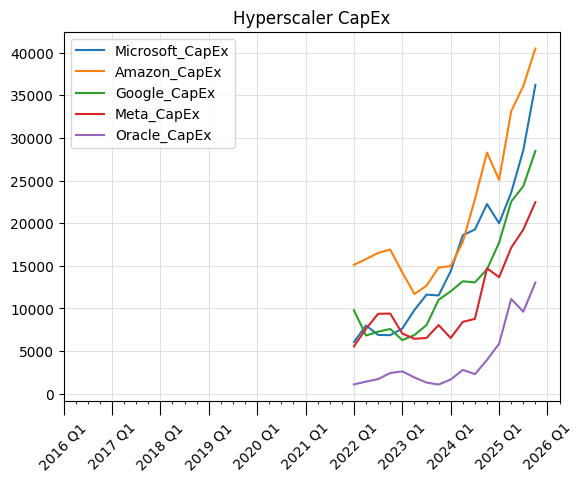

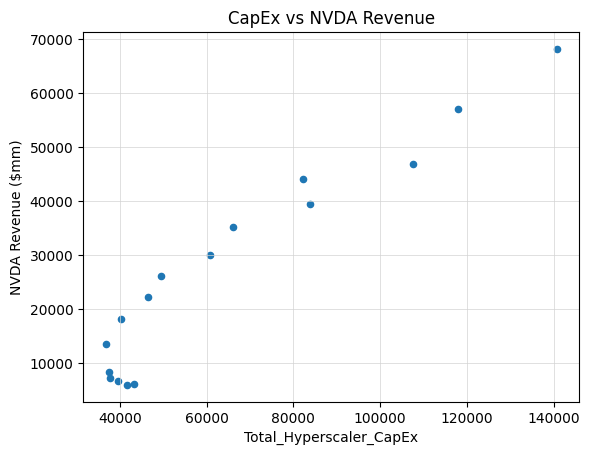

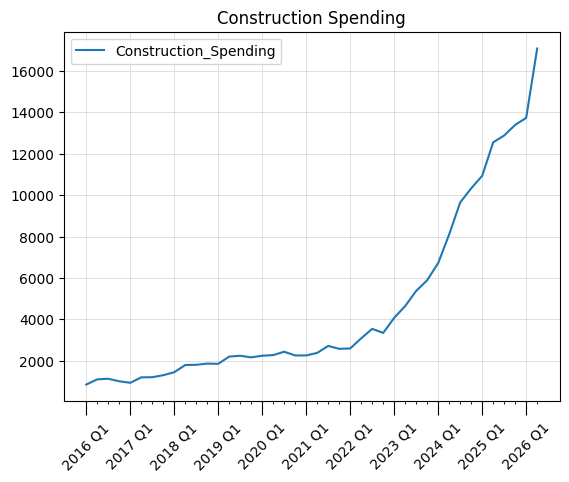

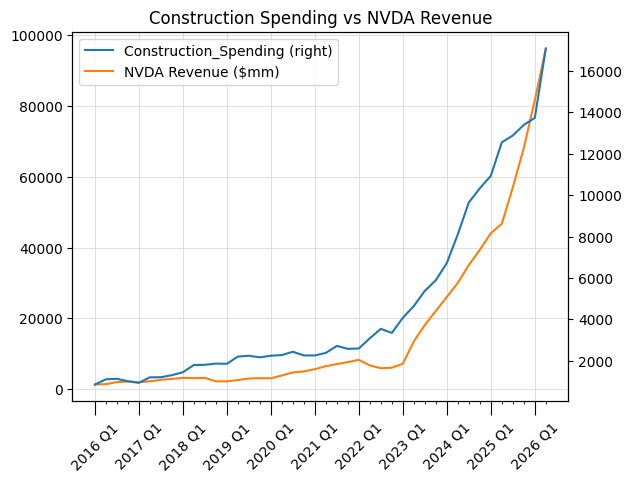

In [ ]:
# visualizations of key trends & distributions
import matplotlib.pyplot as plt

df = combined.sort_values("Quarter").reset_index(drop=True)
labels = [q if "Q1" in q else "" for q in df["Quarter"]]

# Formatting for the time charts: Q1 labels with long ticks, short ticks for other quarters, faint gridlines
def format_chart(ax):
    plt.sca(ax)
    plt.xticks(range(0, len(df), 4), df["Quarter"][::4], rotation=45)
    ax.set_xticks(range(len(df)), minor=True)
    plt.tick_params(axis="x", length=10)
    plt.grid(color="lightgrey", linewidth=0.5)
    plt.show()
    print("\n\n")


# 1. Revenue and cost of revenue over time
format_chart(df.plot(y=["NVDA Revenue ($mm)", "NVDA Cost of Revenue ($mm)"], title="NVDA Revenue vs Cost of Revenue"))

# 2. CapEx by company
format_chart(df.plot(y=["Microsoft_CapEx", "Amazon_CapEx", "Google_CapEx", "Meta_CapEx", "Oracle_CapEx"], title="Hyperscaler CapEx"))

# 3. CapEx vs revenue
df.plot(x="Total_Hyperscaler_CapEx", y="NVDA Revenue ($mm)", kind="scatter", title="CapEx vs NVDA Revenue")
plt.grid(color="lightgrey", linewidth=0.5)
plt.show()
print("\n\n")

# 4. Construction spending over time
format_chart(df.plot(y="Construction_Spending", title="Construction Spending"))

# 5. Construction spending vs NVDA revenue
format_chart(df.plot(y=["Construction_Spending", "NVDA Revenue ($mm)"], secondary_y="Construction_Spending", title="Construction Spending vs NVDA Revenue"))

In [ ]:
# identification of potential issues (missing data, outliers, etc.)

#identifying missing data
missing = combined.isna().sum()
print("Missing Data:")
print(missing[missing > 0])
print("\n\n")

num = combined.select_dtypes(include="number").drop(columns=["Year", "Quarter Number", "SEC Fiscal Year", "Months_Reported"])


Missing Data:
NVDA YoY Revenue Growth     4
NVDA QoQ Revenue Growth     1
Microsoft_CapEx            26
Amazon_CapEx               26
Google_CapEx               26
Meta_CapEx                 26
Oracle_CapEx               26
Total_Hyperscaler_CapEx    26
CapEx_YoY_Growth           30
dtype: int64





In [ ]:
#identifying outliers
# identifying outliers (using quarter-over-quarter growth, because the data is exponential)
key_cols = ["NVDA Data Center Revenue ($mm)", "NVDA Cost of Revenue ($mm)", "NVDA Revenue ($mm)",
            "Total_Hyperscaler_CapEx", "Construction_Spending"]

growth = combined[key_cols].pct_change(fill_method=None)

q1 = growth.quantile(0.25)
q3 = growth.quantile(0.75)
iqr = q3 - q1

print("Outliers (quarter-over-quarter growth):")
for col in key_cols:
    flagged = growth[(growth[col] > q3[col] + 1.5 * iqr[col]) | (growth[col] < q1[col] - 1.5 * iqr[col])].index
    for i in flagged:
        print(f"{col} | {combined.loc[i, 'Quarter']} | {growth.loc[i, col]:+.0%}")

Outliers (quarter-over-quarter growth):
NVDA Data Center Revenue ($mm) | 2016 Q3 | +59%
NVDA Data Center Revenue ($mm) | 2020 Q2 | +64%
NVDA Data Center Revenue ($mm) | 2023 Q2 | +140%
NVDA Cost of Revenue ($mm) | 2018 Q4 | -21%
NVDA Cost of Revenue ($mm) | 2020 Q2 | +48%
NVDA Cost of Revenue ($mm) | 2022 Q3 | -27%
NVDA Cost of Revenue ($mm) | 2022 Q4 | -19%
NVDA Cost of Revenue ($mm) | 2023 Q2 | +59%
NVDA Cost of Revenue ($mm) | 2025 Q1 | +64%
NVDA Cost of Revenue ($mm) | 2025 Q2 | -26%
NVDA Revenue ($mm) | 2016 Q3 | +40%
NVDA Revenue ($mm) | 2018 Q4 | -31%
NVDA Revenue ($mm) | 2022 Q2 | -19%
NVDA Revenue ($mm) | 2023 Q2 | +88%


### Outlier explanation - why we are keeping them
The outlier check flagged 14 quarters. Each one lines up with a real business event, so these are not data errors. Removing them would hide the demand swings our model needs to learn from.

| Quarter | Flagged | Cause |
|---|---|---|
| 2016 Q3 | Revenue, Data Center ↑ | Pascal GPU launch; early AI demand tripled data center sales |
| 2018 Q4 | Revenue, Cost of Revenue ↓ | Crypto-mining crash left excess GPU inventory |
| 2020 Q2 | Data Center, Cost of Revenue ↑ | Mellanox acquisition closed (~14% of revenue) |
| 2022 Q2–Q4 | Revenue, Cost of Revenue ↓ | Gaming slowdown; \$1.32B inventory write-down in Q2 |
| 2023 Q2 | Revenue, Data Center, Cost of Revenue ↑ | Generative AI boom after ChatGPT; H100 demand surged |
| 2025 Q1–Q2 | Cost of Revenue ↑ then ↓ | One-time \$4.5B charge after U.S. export limits on H20 chips to China |

The 2022 and 2025 write-downs are real examples of Nvidia overestimating demand and getting stuck with costly inventory, which is the problem this project aims to address.

## Data Cleaning & Preprocessing  -- Beck

### Handling missing values, duplicates, and outliers
Based on EDA, we found that missing CapEx values occur because the Epoch CapEx dataset begins in 2022, while NVIDIA financial data begins in 2016.
We will not replace these values with zero or an average because doing so would misrepresent actual spending. Instead, CapEx variables will only be included in models using the later period where this data is available. Missing values in NVIDIA growth columns occur naturally because prior-quarter and prior-year values are required to calculate growth rates. These values will remain missing and will not be used as predictors when unavailable. The outlier analysis identified real business events—including the cryptocurrency downturn, rapid generative-AI growth, and export-related inventory charges—rather than errors. Therefore, all outliers will be retained.

### Encoding categorical variables:
All of our predictors are numeric so there is no need for encoding variables.

#### Scaling and Normalization

The predictor variables are going to be log-transformed to reduce the effect of
large values and rapid growth. For models that require scaling, such as
Ridge Regression, we will use StandardScaler to put the predictors on a
comparable scale. The scaler will be fitted using only the training data
and then applied to both the training and testing data.

### Feature Engineering

In [ ]:
# 1. Convert Quarter End into a Date format
combined['Quarter End'] = pd.to_datetime(
    combined['Quarter End'],
    errors='coerce'
)

print("Quarter End conversion complete.")
print("Missing Quarter End dates:", combined["Quarter End"].isna().sum())

display(combined[["quarter", "Quarter End"]].head())

Quarter End conversion complete.
Missing Quarter End dates: 0


,quarter,Quarter End
0,2016Q1,2016-05-01
1,2016Q2,2016-07-31
2,2016Q3,2016-10-30
3,2016Q4,2017-01-29
4,2017Q1,2017-04-30


The Quarter End column was converted to a datetime format. This allows the dataset to be sorted, plotted, and split chronologically for time-series forecasting.

In [ ]:
# 2. Set NVIDIA next quarter cost of revenue as the target variable
# Shifting the Cost of Revenue column up by 1 to align next quarter's target with current quarter's features
combined = combined.sort_values("Quarter End").reset_index(drop=True)

combined["target_next_quarter_cost_of_revenue"] = (
    combined["NVDA Cost of Revenue ($mm)"].shift(-1)
)
print("Target variable 'target_next_quarter_cost_of_revenue' created.")
print("Missing values in target:", combined['target_next_quarter_cost_of_revenue'].isna().sum())

Target variable 'target_next_quarter_cost_of_revenue' created.
Missing values in target: 1


The final observation does not have next-quarter cost-of-revenue data available. Because it cannot be used to train or evaluate the forecasting models, we remove it from the modeling dataset.

In [ ]:
# Remove the final row because next-quarter target data is unavailable
combined_cleaned = combined.dropna(
    subset=["target_next_quarter_cost_of_revenue"]
).copy()

print("Rows before removing blank target:", len(combined))
print("Rows after removing blank target:", len(combined_cleaned))

Rows before removing blank target: 42
Rows after removing blank target: 41


In [ ]:
# 3. Use a log transformation (log1p) for columns with exponential shapes
# Log-transform predictor columns with exponential growth
exponential_cols = [
    "NVDA Revenue ($mm)",
    "NVDA Cost of Revenue ($mm)",
    "NVDA Data Center Revenue ($mm)",
    "Construction_Spending"
]

for col in exponential_cols:
    combined_cleaned[f"{col}_log"] = np.log1p(combined_cleaned[col])

print("Log-transformed predictor columns created:")
print([col for col in combined_cleaned.columns if "_log" in col])

Log-transformed predictor columns created:
['NVDA Revenue ($mm)_log', 'NVDA Cost of Revenue ($mm)_log', 'NVDA Data Center Revenue ($mm)_log', 'Construction_Spending_log']


In [ ]:
# Log-transform next-quarter cost of revenue
combined_cleaned["target_next_quarter_cost_of_revenue_log"] = np.log1p(
    combined_cleaned["target_next_quarter_cost_of_revenue"]
)

### Selecting Predictors and Target Variable

| Predictor | Why include it? |
|---|---|
| Current-quarter cost of revenue | Recent costs are a starting point for forecasting next-quarter costs |
| Current-quarter total revenue | Sales levels may relate to the cost of generating future sales |
| Current-quarter Data Center revenue | Captures NVIDIA’s recent data-center business activity |
| Current-quarter construction spending | Provides context on data-center infrastructure investment |

In [ ]:
# Choose the predictor columns
predictors = [
    "NVDA Cost of Revenue ($mm)_log",
    "NVDA Revenue ($mm)_log",
    "NVDA Data Center Revenue ($mm)_log",
    "Construction_Spending_log"
]

X = combined_cleaned[predictors]
y = combined_cleaned["target_next_quarter_cost_of_revenue_log"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (41, 4)
Target shape: (41,)


### Checking Selected Variables for Missing Values

In [ ]:
print("Missing predictor values:")
print(X.isna().sum())
print("Missing target values:", y.isna().sum())

Missing predictor values:
NVDA Cost of Revenue ($mm)_log        0
NVDA Revenue ($mm)_log                0
NVDA Data Center Revenue ($mm)_log    0
Construction_Spending_log             0
dtype: int64
Missing target values: 0


## Modeling Approach - Mikayla

### Rationale for model selection (why we chose each algorithm)

 Under the current market conditions, demand is projected to keep increasing. What is unknown is how quickly, and what factors it's resting on. Also, becuase this is such a new problem, there isn't a lot of data available to use to predict swings in demand.

Becasue of this, we will be using regression models that work well on small datasets, with the goal of identifying which features are the best predictors of "demand" via predicting next quarter's cost of revenue.

Firstly, a simple linear regression excluding the CAPEX columns, to explore relationships between each of the features and the target (avoiding our biggest limitation). Then, running it again with the CAPEX included, and the rows with nulls in those rows discarded. Whichever model performs better will tell us if CAPEX spend is a good predictor or not, and also show us just how limiting the CAPEX data might be.

Then, for similar reasons, a SVR regression model using a linear kernel (becuase the data has been log transformed already) and a KNN regression. Both handle small datasets reasonably well, and will give better comparative insight agains the classic regression model.

### Description of 3 models

1. Two versions of a simple linear regression. Fits a line between predictors and target. One including CAPEX Data, and one without. No scaler needed. Tuning includes feature selection. Evaluation is on MSE and R2.

2. SVR (Support vector regression). Fits a curve that keeps most points within a given margin. Scaler required (to fit only on training data, and apply to testing data). Tuning by comparing linear, RBF, and polynomial kernels, and then determining C. Evaluating on MSE and R2.

3. KNN Regression. Predicts next value off of most similar past values. Scaler required (to fit only on training data, and apply to testing data). Tune by testing different values of K. Evaluate on MSE and R2.

For all three models, convert the value back to dollars (reverse the log transformation) by using np.exm1 before evaluation.

### Train/test split or cross-validation approach
For all three, we will use a time based, 80/20, train test split. We chose time based becasue the business problem requires us to predict what happens in the future using past data, so using a random split would lead to improper fitting of the model. We chose to use 80/20 because larger splits, (60/40 etc.) would mean the model training would miss the AI boom in newer quarters.

For the CAPEX linear regression version, use the same train/test split, but after dropping the rows with missing data.

## Model Implementation 1 - Simple regression with and without CapEx data -- Nathan

In [ ]:
# Model Code

In [ ]:
# Model Tuning

In [ ]:
# Model Final Settings (post tuning)

In [ ]:
# Feature Selection Steps

 ## Model Implementation 2 - SVR  -- Beck

In [ ]:
# Model Tuning

In [ ]:
# Model Final Settings (post tuning)

In [ ]:
# Feature Selection Steps

## Model Implementation 3 - KNN Regression -- Billy

In [ ]:
# Model Code

In [ ]:
# Model Tuning

In [ ]:
# Model Final Settings (post tuning)

In [ ]:
# Feature Selection Steps

## Model Evaluation -- Mikayla

In [ ]:
# Evaluate Model 1

In [ ]:
# Evaluate Model 2

In [ ]:
# Evaluate Model 3

In [ ]:
# Comparison of models

### Interpretation of model results & evaluation:


## Conclusions & Recommendations - Billy

### Best model choice and why

### Clear business recommendations

### Suggestions for next steps or further analysis

## Final Descriptive Charts - Nathan

Make sure all charts are labeled, correctly outputted, and have ocnsistent formatting

In [ ]:
# chart 1

In [ ]:
# chart 2

In [ ]:
# chart 3

In [ ]:
# chart 4

In [ ]:
# chart 5

In [ ]:
# chart 6 (optional)